# Comparison of Six Regression Algorithms
**Dataset:** Diabetes regression dataset  
**Input:** BMI  
**Target:** Disease progression score

Name: Muhammad Yahya Tamimy Registration number:FA23-BAI-020

Each model is trained and evaluated separately. All six use the same 80:20 split. Run the notebook from top to bottom. The final section compares their results. Saved outputs are included from a completed run.

## 1. Import libraries

In [ ]:
# If a package is missing in Colab, uncomment and run the next line.
# %pip install numpy pandas matplotlib scikit-learn xgboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor

import sklearn
import xgboost
print('scikit-learn:', sklearn.__version__)
print('XGBoost:', xgboost.__version__)

scikit-learn: 1.8.0
XGBoost: 3.4.1


## 2. Load and inspect the dataset
This real dataset has 442 records and 10 available features. We select BMI only for every model so the same problem can later be demonstrated by hand. The target is a numerical progression score, not classification accuracy or a diagnosis. Loading `scaled=False` preserves raw input units.

Source: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html

In [ ]:
data = load_diabetes(as_frame=True, scaled=False)
df = data.data[['bmi']].copy()
df['progression'] = data.target
print(df.head().to_string(index=False))
print('Dataset shape:', df.shape)

 bmi  progression
32.1        151.0
21.6         75.0
30.5        141.0
25.3        206.0
23.0        135.0
Dataset shape: (442, 2)


In [ ]:
print('Missing values:')
print(df.isnull().sum())
print('Summary:')
print(df.describe().round(2).to_string())

Missing values:
bmi            0
progression    0
dtype: int64
Summary:
          bmi  progression
count  442.00       442.00
mean    26.38       152.13
std      4.42        77.09
min     18.00        25.00
25%     23.20        87.00
50%     25.70       140.50
75%     29.28       211.50
max     42.20       346.00


## 3. Split the dataset once
Reuse these exact training and test records for all six models. Integer rounding gives 353 training records and 89 test records.

In [ ]:
X = df[['bmi']]
y = df['progression']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print('Training records:', len(X_train))
print('Testing records:', len(X_test))

Training records: 353
Testing records: 89


## 4. Preprocess the training and test data
There are no missing values, but median imputation is included as a precaution. Fit the imputer and scalers on training data only. Apply their learned transformations to the test set. KNN and the neural network use scaled inputs; the other models use inputs in original units.

In [ ]:
imputer = SimpleImputer(strategy='median')
X_train_clean = imputer.fit_transform(X_train)
X_test_clean = imputer.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test_clean)
print('Preprocessing completed using training data only.')

Preprocessing completed using training data only.


In [ ]:
# Scale training targets for the neural network only.
# Its predictions will be converted back to original score units.
target_scaler = StandardScaler()
y_train_scaled = target_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

# Use identical axes for the six actual-versus-predicted graphs.
plot_min = 0
plot_max = 400

For each model: train, predict, calculate metrics, then plot actual versus predicted values. Lower MAE, MSE and RMSE are better; higher R² is better. R² is not classification accuracy. Settings are fixed before test evaluation.

## 5. Linear Regression
Fits a straight-line relationship between BMI and progression.

**Train the model**

In [ ]:
linear_model = LinearRegression()
linear_model.fit(X_train_clean, y_train)
print("Linear Regression training completed.")

Linear Regression training completed.


**Predict the test values**

In [ ]:
pred_lr = linear_model.predict(X_test_clean)
print('First five predictions:', np.round(pred_lr[:5], 2))

First five predictions: [145.81 188.86 147.96 203.93 131.81]


**Calculate MAE, MSE, RMSE and R²**

In [ ]:
mae_lr = mean_absolute_error(y_test, pred_lr)
mse_lr = mean_squared_error(y_test, pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, pred_lr)

print('MAE :', round(mae_lr, 4))
print('MSE :', round(mse_lr, 4))
print('RMSE:', round(rmse_lr, 4))
print('R²  :', round(r2_lr, 4))

MAE : 52.26
MSE : 4061.8259
RMSE: 63.7325
R²  : 0.2334


**Plot actual versus predicted values**

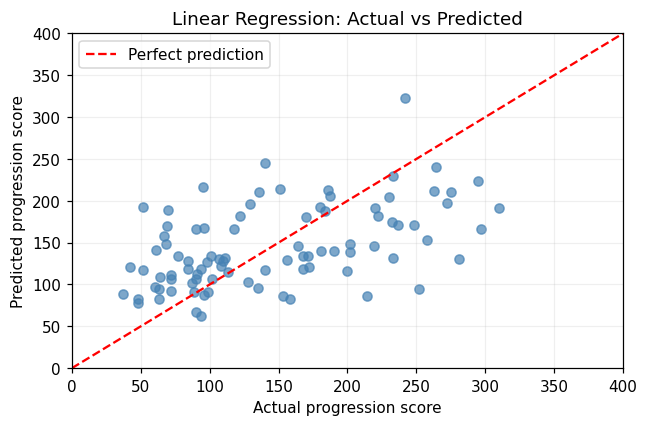

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(y_test, pred_lr, alpha=0.7, color='steelblue')
plt.plot([plot_min, plot_max], [plot_min, plot_max], 'r--', label='Perfect prediction')
plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)
plt.xlabel('Actual progression score')
plt.ylabel('Predicted progression score')
plt.title('Linear Regression: Actual vs Predicted')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Decision Tree Regression
Splits BMI into regions and predicts the average target in each leaf.

**Train the model**

In [ ]:
tree_model = DecisionTreeRegressor(
    max_depth=3, min_samples_leaf=5, random_state=42
)
tree_model.fit(X_train_clean, y_train)
print("Decision Tree training completed.")

Decision Tree training completed.


**Predict the test values**

In [ ]:
pred_dt = tree_model.predict(X_test_clean)
print('First five predictions:', np.round(pred_dt[:5], 2))

First five predictions: [144.52 193.69 144.52 193.69 130.9 ]


**Calculate MAE, MSE, RMSE and R²**

In [ ]:
mae_dt = mean_absolute_error(y_test, pred_dt)
mse_dt = mean_squared_error(y_test, pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, pred_dt)

print('MAE :', round(mae_dt, 4))
print('MSE :', round(mse_dt, 4))
print('RMSE:', round(rmse_dt, 4))
print('R²  :', round(r2_dt, 4))

MAE : 52.1313
MSE : 4130.668
RMSE: 64.2703
R²  : 0.2204


**Plot actual versus predicted values**

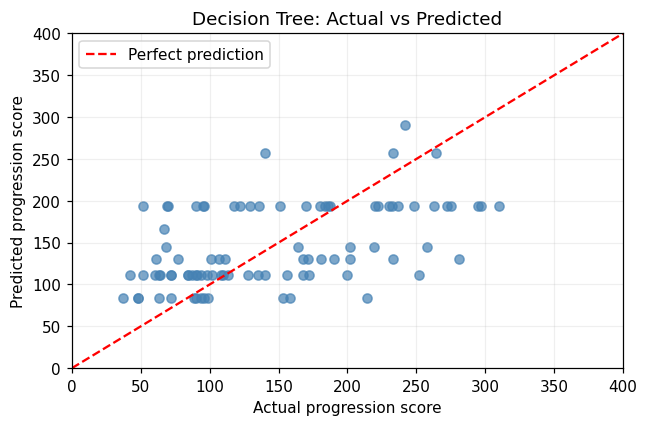

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(y_test, pred_dt, alpha=0.7, color='steelblue')
plt.plot([plot_min, plot_max], [plot_min, plot_max], 'r--', label='Perfect prediction')
plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)
plt.xlabel('Actual progression score')
plt.ylabel('Predicted progression score')
plt.title('Decision Tree: Actual vs Predicted')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 7. Random Forest Regression
Fits many trees on bootstrap samples and averages their predictions.

**Train the model**

In [ ]:
forest_model = RandomForestRegressor(
    n_estimators=200, max_depth=4, min_samples_leaf=5,
    random_state=42, n_jobs=1
)
forest_model.fit(X_train_clean, y_train)
print("Random Forest training completed.")

Random Forest training completed.


**Predict the test values**

In [ ]:
pred_rf = forest_model.predict(X_test_clean)
print('First five predictions:', np.round(pred_rf[:5], 2))

First five predictions: [156.61 177.21 144.11 196.32 125.7 ]


**Calculate MAE, MSE, RMSE and R²**

In [ ]:
mae_rf = mean_absolute_error(y_test, pred_rf)
mse_rf = mean_squared_error(y_test, pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, pred_rf)

print('MAE :', round(mae_rf, 4))
print('MSE :', round(mse_rf, 4))
print('RMSE:', round(rmse_rf, 4))
print('R²  :', round(r2_rf, 4))

MAE : 51.1834
MSE : 4097.0918
RMSE: 64.0085
R²  : 0.2267


**Plot actual versus predicted values**

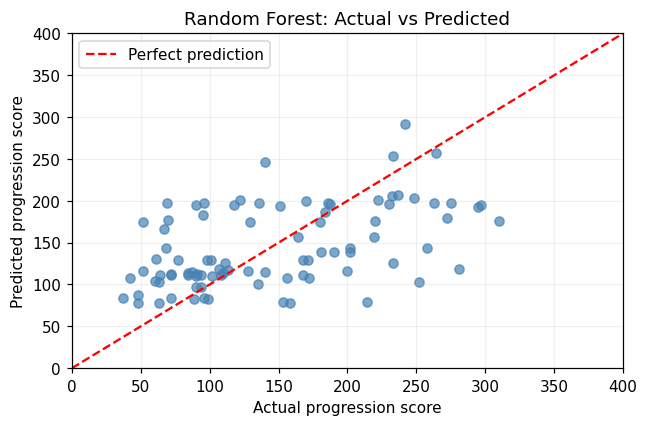

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(y_test, pred_rf, alpha=0.7, color='steelblue')
plt.plot([plot_min, plot_max], [plot_min, plot_max], 'r--', label='Perfect prediction')
plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)
plt.xlabel('Actual progression score')
plt.ylabel('Predicted progression score')
plt.title('Random Forest: Actual vs Predicted')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8. Neural Network Regression
Uses two hidden layers with 16 and 8 neurons. Inputs and training targets are standardized.

**Train the model**

In [ ]:
neural_model = MLPRegressor(
    hidden_layer_sizes=(16, 8), activation='relu', solver='lbfgs',
    alpha=0.1, max_iter=5000, max_fun=100000, random_state=42
)
neural_model.fit(X_train_scaled, y_train_scaled)
print("Neural Network training completed.")

Neural Network training completed.


**Predict the test values**

In [ ]:
pred_nn_scaled = neural_model.predict(X_test_scaled)
pred_nn = target_scaler.inverse_transform(
    pred_nn_scaled.reshape(-1, 1)
).ravel()
print('First five predictions:', np.round(pred_nn[:5], 2))

First five predictions: [137.75 184.58 140.27 191.22 121.35]


**Calculate MAE, MSE, RMSE and R²**

In [ ]:
mae_nn = mean_absolute_error(y_test, pred_nn)
mse_nn = mean_squared_error(y_test, pred_nn)
rmse_nn = np.sqrt(mse_nn)
r2_nn = r2_score(y_test, pred_nn)

print('MAE :', round(mae_nn, 4))
print('MSE :', round(mse_nn, 4))
print('RMSE:', round(rmse_nn, 4))
print('R²  :', round(r2_nn, 4))

MAE : 52.5289
MSE : 4294.9432
RMSE: 65.5358
R²  : 0.1894


**Plot actual versus predicted values**

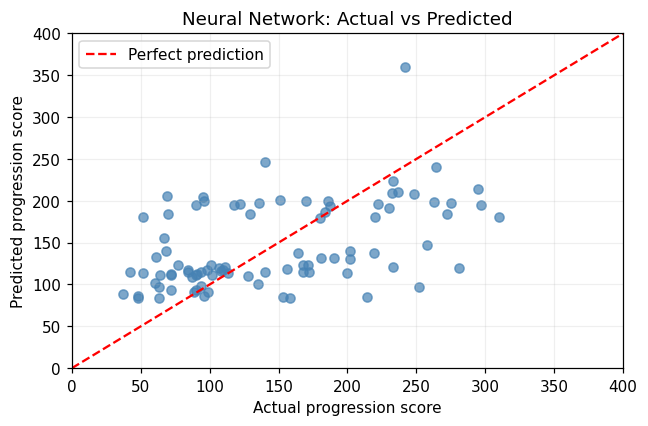

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(y_test, pred_nn, alpha=0.7, color='steelblue')
plt.plot([plot_min, plot_max], [plot_min, plot_max], 'r--', label='Perfect prediction')
plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)
plt.xlabel('Actual progression score')
plt.ylabel('Predicted progression score')
plt.title('Neural Network: Actual vs Predicted')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 9. XGBoost Regression
Builds trees sequentially to correct earlier errors, with regularization.

**Train the model**

In [ ]:
xgb_model = XGBRegressor(
    objective='reg:squarederror', n_estimators=200, max_depth=2,
    learning_rate=0.03, reg_lambda=1.0, subsample=1.0,
    colsample_bytree=1.0, random_state=42, n_jobs=1
)
xgb_model.fit(X_train_clean, y_train)
print("XGBoost training completed.")

XGBoost training completed.


**Predict the test values**

In [ ]:
pred_xgb = xgb_model.predict(X_test_clean)
print('First five predictions:', np.round(pred_xgb[:5], 2))

First five predictions: [150.47 177.75 144.03 196.16 132.62]


**Calculate MAE, MSE, RMSE and R²**

In [ ]:
mae_xgb = mean_absolute_error(y_test, pred_xgb)
mse_xgb = mean_squared_error(y_test, pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
r2_xgb = r2_score(y_test, pred_xgb)

print('MAE :', round(mae_xgb, 4))
print('MSE :', round(mse_xgb, 4))
print('RMSE:', round(rmse_xgb, 4))
print('R²  :', round(r2_xgb, 4))

MAE : 51.2092
MSE : 3983.4308
RMSE: 63.1144
R²  : 0.2481


**Plot actual versus predicted values**

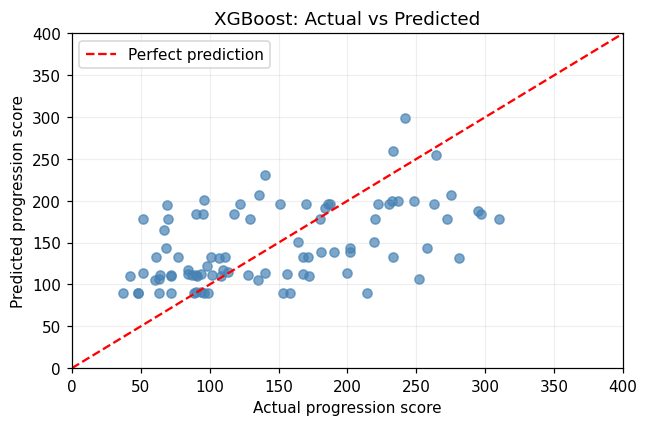

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(y_test, pred_xgb, alpha=0.7, color='steelblue')
plt.plot([plot_min, plot_max], [plot_min, plot_max], 'r--', label='Perfect prediction')
plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)
plt.xlabel('Actual progression score')
plt.ylabel('Predicted progression score')
plt.title('XGBoost: Actual vs Predicted')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 10. KNN Regression
Predicts the average target among the 15 nearest training observations.

**Train the model**

In [ ]:
knn_model = KNeighborsRegressor(n_neighbors=15, weights='uniform')
knn_model.fit(X_train_scaled, y_train)
print("KNN training completed.")

KNN training completed.


**Predict the test values**

In [ ]:
pred_knn = knn_model.predict(X_test_scaled)
print('First five predictions:', np.round(pred_knn[:5], 2))

First five predictions: [150.4  174.6  129.53 220.   121.  ]


**Calculate MAE, MSE, RMSE and R²**

In [ ]:
mae_knn = mean_absolute_error(y_test, pred_knn)
mse_knn = mean_squared_error(y_test, pred_knn)
rmse_knn = np.sqrt(mse_knn)
r2_knn = r2_score(y_test, pred_knn)

print('MAE :', round(mae_knn, 4))
print('MSE :', round(mse_knn, 4))
print('RMSE:', round(rmse_knn, 4))
print('R²  :', round(r2_knn, 4))

MAE : 50.7154
MSE : 4166.4215
RMSE: 64.5478
R²  : 0.2136


**Plot actual versus predicted values**

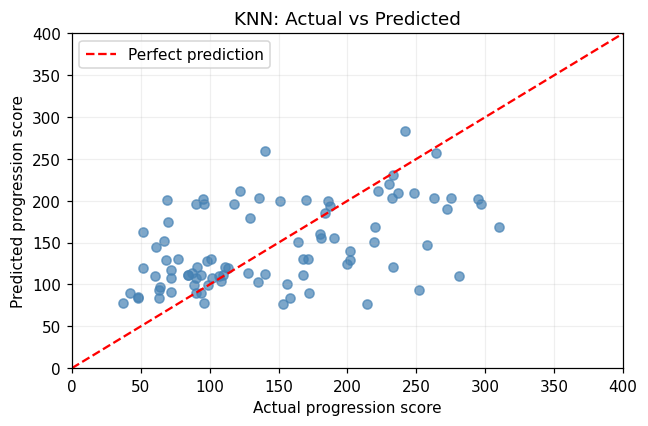

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(y_test, pred_knn, alpha=0.7, color='steelblue')
plt.plot([plot_min, plot_max], [plot_min, plot_max], 'r--', label='Perfect prediction')
plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)
plt.xlabel('Actual progression score')
plt.ylabel('Predicted progression score')
plt.title('KNN: Actual vs Predicted')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 11. Compare all six models
Create this table after executing every model section. MAE and RMSE use progression-score units; MSE uses squared units. The primary ranking criterion is the lowest test RMSE. The table is rebuilt from the six saved sets of metrics, so rerunning it does not duplicate rows.

In [ ]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest',
              'Neural Network', 'XGBoost', 'KNN'],
    'MAE': [mae_lr, mae_dt, mae_rf, mae_nn, mae_xgb, mae_knn],
    'MSE': [mse_lr, mse_dt, mse_rf, mse_nn, mse_xgb, mse_knn],
    'RMSE': [rmse_lr, rmse_dt, rmse_rf, rmse_nn, rmse_xgb, rmse_knn],
    'R²': [r2_lr, r2_dt, r2_rf, r2_nn, r2_xgb, r2_knn]
})

comparison = comparison.sort_values('RMSE').reset_index(drop=True)
print(comparison.round(4).to_string(index=False))

            Model     MAE       MSE    RMSE     R²
          XGBoost 51.2092 3983.4308 63.1144 0.2481
Linear Regression 52.2600 4061.8259 63.7325 0.2334
    Random Forest 51.1834 4097.0918 64.0085 0.2267
    Decision Tree 52.1313 4130.6680 64.2703 0.2204
              KNN 50.7154 4166.4215 64.5478 0.2136
   Neural Network 52.5289 4294.9432 65.5358 0.1894


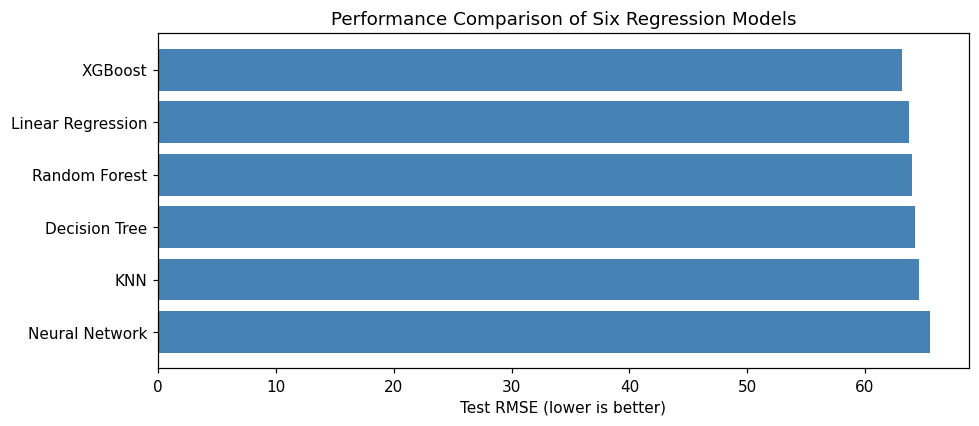

In [ ]:
plt.figure(figsize=(9, 4))
plt.barh(comparison['Model'], comparison['RMSE'], color='steelblue')
plt.gca().invert_yaxis()
plt.xlabel('Test RMSE (lower is better)')
plt.title('Performance Comparison of Six Regression Models')
plt.tight_layout()
plt.show()

## 12. Identify the best model

In [ ]:
best_rmse = comparison.loc[comparison['RMSE'].idxmin()]
best_mae = comparison.loc[comparison['MAE'].idxmin()]

print('Best model by RMSE:', best_rmse['Model'])
print('RMSE:', round(best_rmse['RMSE'], 4))
print('R²:', round(best_rmse['R²'], 4))
print('Best model by MAE:', best_mae['Model'])
print('MAE:', round(best_mae['MAE'], 4))

Best model by RMSE: XGBoost
RMSE: 63.1144
R²: 0.2481
Best model by MAE: KNN
MAE: 50.7154


In the saved run, XGBoost has the lowest RMSE and KNN has the lowest MAE. RMSE penalizes large errors more strongly, so these rankings can differ. XGBoost is the selected winner because RMSE is the stated primary criterion. Its improvement over Linear Regression is small.

This conclusion applies to this dataset, BMI-only feature set, split and fixed settings. BMI alone leaves substantial variation unexplained. A stronger follow-up would use all available features and tune each model with training-only cross-validation, keeping the test set untouched until final evaluation.

## 13. Strengths and limitations
| Model | Strength | Limitation |
|---|---|---|
| Linear Regression | Simple, fast and interpretable | Assumes a linear relationship |
| Decision Tree | Captures nonlinear thresholds | Can overfit and produce unstable splits |
| Random Forest | Averaging reduces tree variance | Less interpretable; one feature limits diversity |
| Neural Network | Learns flexible nonlinear patterns | Needs scaling and careful training |
| XGBoost | Corrects errors sequentially with regularization | Sensitive to model settings and noise |
| KNN | Simple local averaging | Sensitive to k; weak extrapolation |


## 14. Save the final results

In [ ]:
comparison.to_csv('regression_comparison.csv', index=False)

test_predictions = pd.DataFrame({
    'Actual': y_test,
    'Linear Regression': pred_lr,
    'Decision Tree': pred_dt,
    'Random Forest': pred_rf,
    'Neural Network': pred_nn,
    'XGBoost': pred_xgb,
    'KNN': pred_knn
})
test_predictions.to_csv('regression_predictions.csv', index_label='record_id')
print('Saved regression_comparison.csv and regression_predictions.csv')

Saved regression_comparison.csv and regression_predictions.csv


## References
- Dataset: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html
- Models: https://scikit-learn.org/stable/supervised_learning.html
- Metrics: https://scikit-learn.org/stable/modules/model_evaluation.html
- XGBoost: https://xgboost.readthedocs.io/en/stable/parameter.html